# 05 — Макро-контроли FRED

Цель: понять, как устроены дневные и месячные макро-контроли FRED (пропуски, календари, публикационные лаги,
стационарность, коллинеарность), насколько они связаны с ценой WTI и спредом F1−F2 и годятся ли
они как контроли для недельной модели inventory surprise без утечки будущей информации.

Файлы (`eda/data/processed/`):
- `fred/fred_daily_features.parquet` — 9 дневных рядов (уровни + изменения `1obs`/`5obs`), календарные дни;
- `fred/fred_monthly_features_current.parquet` — CPI, промпроизводство, безработица (текущая пересмотренная версия);
- `market/barchart_wti_curve_2015_onward.parquet` — F1, F2 и спред F1−F2 по торговым дням;
- `u.release_frame()` — недельная таблица релизов EIA (surprise, консенсус).

Дополнительно читаются только сохранённые выходы ноутбука сбора `jup_files/data/02_fred_macro.ipynb`
(метаданные FRED и выдержки initial-release) — сами файлы с первыми публикациями на этой машине отсутствуют.

In [1]:
import sys
import warnings
from io import StringIO
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pandas.tseries.holiday import USFederalHolidayCalendar
from pandas.tseries.offsets import Easter
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller

import eda_utils as u

u.setup_style()
# eda_utils.report_week использует устаревший в pandas 3 .dt.dayofweek; модуль не меняем, глушим только это предупреждение
warnings.filterwarnings("ignore", message="Series.dt.dayofweek is deprecated")

daily = u.load("fred/fred_daily_features.parquet")
monthly = u.load("fred/fred_monthly_features_current.parquet")
curve = u.load("market/barchart_wti_curve_2015_onward.parquet")
rel = u.release_frame()

LEVELS = ["usd_broad", "vix", "fed_funds", "treasury_2y", "treasury_10y",
          "yield_curve_10y2y", "real_yield_10y", "breakeven_10y", "baa_spread"]
SERIES_ID = {"usd_broad": "DTWEXBGS", "vix": "VIXCLS", "fed_funds": "DFF", "treasury_2y": "DGS2",
             "treasury_10y": "DGS10", "yield_curve_10y2y": "T10Y2Y", "real_yield_10y": "DFII10",
             "breakeven_10y": "T10YIE", "baa_spread": "BAA10Y"}
LABEL = {"usd_broad": "USD broad", "vix": "VIX", "fed_funds": "Fed funds", "treasury_2y": "UST 2y",
         "treasury_10y": "UST 10y", "yield_curve_10y2y": "10y−2y", "real_yield_10y": "Реальная 10y",
         "breakeven_10y": "Breakeven 10y", "baa_spread": "BAA спред"}
# столбцы готовых изменений из файла
CHG1 = {c: (f"{c}_change_1obs_bp" if c not in ("usd_broad", "vix") else
            ("usd_broad_return_1obs_pct" if c == "usd_broad" else "vix_change_1obs")) for c in LEVELS}
CHG5 = {c: v.replace("1obs", "5obs") for c, v in CHG1.items()}

print("daily:", daily.shape, daily["date"].min().date(), "→", daily["date"].max().date(),
      "| дубликаты дат:", daily["date"].duplicated().sum(),
      "| шаг 1 день везде:", (daily["date"].diff().dropna() == pd.Timedelta(days=1)).all())
print("monthly:", monthly.shape, monthly["date"].min().date(), "→", monthly["date"].max().date())
print("curve:", curve.shape, curve["trading_day"].min().date(), "→", curve["trading_day"].max().date())
print("releases:", rel.shape, rel["release_date"].min().date(), "→", rel["release_date"].max().date())

daily: (4276, 28) 2015-02-19 → 2026-11-03 | дубликаты дат: 0 | шаг 1 день везде: True
monthly: (140, 7) 2015-02-01 → 2026-09-01
curve: (2981, 27) 2015-01-02 → 2026-11-05
releases: (616, 7) 2015-01-07 → 2026-11-04


In [2]:
# Метаданные FRED, сохранённые в выходах ноутбука сбора (снимок на момент выгрузки 2026-11-04)
nb02 = json.loads((Path.cwd().parents[1] / "jup_files/data/02_fred_macro.ipynb").read_text(encoding="utf-8"))


def nb02_table(marker: str) -> pd.DataFrame:
    """HTML-таблица из выхода той ячейки ноутбука 02, исходник которой содержит `marker`."""
    for cell in nb02["cells"]:
        if cell["cell_type"] == "code" and marker in "".join(cell["source"]):
            for out in cell.get("outputs", []):
                html = out.get("data", {}).get("text/html")
                if html:
                    table = pd.read_html(StringIO("".join(html)), index_col=0)[0]
                    if isinstance(table.columns, pd.MultiIndex):  # у describe() второй уровень — имя индекса
                        table.columns = table.columns.get_level_values(0)
                    return table
    raise LookupError(marker)


meta = nb02_table("metadata_rows = []")
meta[["name", "series_id", "frequency", "units", "observation_end", "last_updated"]]

,name,series_id,frequency,units,observation_end,last_updated
0,usd_broad,DTWEXBGS,Daily,Index Jan 2006=100,2026-10-30,2026-11-02 15:51:35-06
1,vix,VIXCLS,"Daily, Close",Index,2026-11-03,2026-11-04 08:37:31-06
2,fed_funds,DFF,"Daily, 7-Day",Percent,2026-11-02,2026-11-03 15:16:31-06
3,treasury_2y,DGS2,Daily,Percent,2026-11-02,2026-11-03 15:16:27-06
4,treasury_10y,DGS10,Daily,Percent,2026-11-02,2026-11-03 15:16:31-06
5,yield_curve_10y2y,T10Y2Y,Daily,Percent,2026-11-03,2026-11-03 16:02:33-06
6,real_yield_10y,DFII10,Daily,Percent,2026-11-02,2026-11-03 15:16:27-06
7,breakeven_10y,T10YIE,Daily,Percent,2026-11-03,2026-11-03 16:03:26-06
8,baa_spread,BAA10Y,Daily,Percent,2026-11-02,2026-11-03 16:02:32-06
9,cpi,CPIAUCSL,Monthly,Index 1982-1984=100,2026-09-01,2026-10-14 08:08:29-05


## 1. Пропуски и календари

Проверяем, что ~30% NA — это выходные и праздники, а не дыры в данных. Праздники: федеральный
календарь США (`USFederalHolidayCalendar`) и Страстная пятница (биржи закрыты, но это не федеральный праздник).

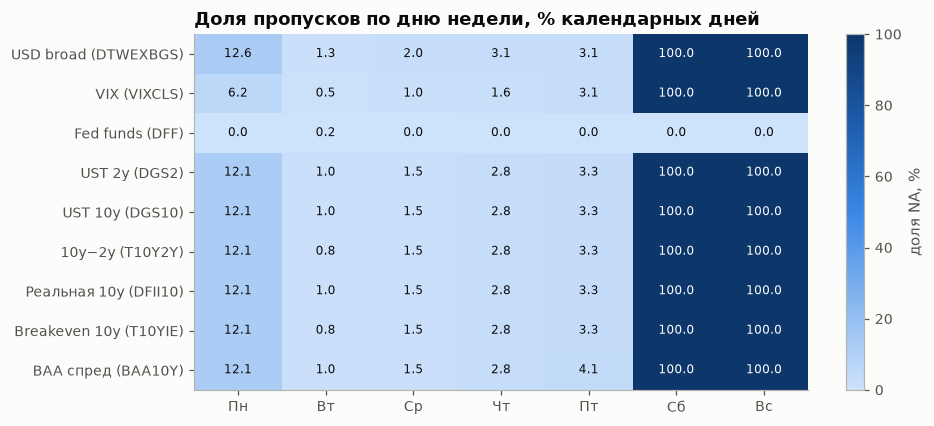

In [3]:
d = daily.copy()
d["dow"] = d["date"].dt.day_of_week
DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
na_by_dow = d.groupby("dow")[LEVELS].apply(lambda g: g.isna().mean() * 100).T
na_by_dow.columns = DOW

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(na_by_dow.to_numpy(), cmap=u.SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(7), DOW)
ax.set_yticks(range(len(LEVELS)), [f"{LABEL[c]} ({SERIES_ID[c]})" for c in LEVELS])
ax.grid(False)
for i in range(len(LEVELS)):
    for j in range(7):
        v = na_by_dow.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if v > 50 else u.INK)
fig.colorbar(im, ax=ax, label="доля NA, %")
ax.set_title("Доля пропусков по дню недели, % календарных дней")
plt.show()

In [4]:
hol = USFederalHolidayCalendar().holidays("2015-01-01", "2026-12-31")
good_friday = pd.DatetimeIndex([pd.Timestamp(f"{y}-01-01") + Easter() - pd.Timedelta(days=2)
                                for y in range(2015, 2027)])
wk = d[d["dow"] < 5]
rows, other = [], {}
for c in LEVELS:
    na = wk.loc[wk[c].isna(), "date"]
    is_hol, is_gf = na.isin(hol), na.isin(good_friday)
    rows.append({"ряд": c, "NA всего": int(d[c].isna().sum()), "NA в выходные": int(d[c].isna().sum() - len(na)),
                 "NA будни: фед. праздник": int(is_hol.sum()), "NA будни: Страстная пятница": int(is_gf.sum()),
                 "NA будни: прочее": int((~is_hol & ~is_gf).sum())})
    other[c] = na[~is_hol & ~is_gf].dt.strftime("%Y-%m-%d").tolist()
na_table = pd.DataFrame(rows).set_index("ряд")
# федеральные праздники, в которые ряд при этом наблюдается (биржа работает, рынок облигаций закрыт и т.п.)
hol_wk = hol[(hol >= d["date"].min()) & (hol <= d["date"].max()) & (hol.day_of_week < 5)]
na_table["наблюдается в фед. праздник"] = [int(d.set_index("date").loc[hol_wk, c].notna().sum()) for c in LEVELS]
na_table["наблюдается в Страстную пятницу"] = [
    int(d.set_index("date").reindex(good_friday)[c].notna().sum()) for c in LEVELS]
print("будних федеральных праздников в окне:", len(hol_wk), "| Страстных пятниц:",
      int(((good_friday >= d["date"].min()) & (good_friday <= d["date"].max())).sum()))
na_table

будних федеральных праздников в окне: 120 | Страстных пятниц: 12


,NA всего,NA в выходные,NA будни: фед. праздник,NA будни: Страстная пятница,NA будни: прочее,наблюдается в фед. праздник,наблюдается в Страстную пятницу
ряд,,,,,,,
usd_broad,1357,1222,119,0,16,1,12
vix,1298,1222,63,12,1,57,0
fed_funds,1,0,0,0,1,120,12
treasury_2y,1348,1222,116,8,2,4,4
treasury_10y,1348,1222,116,8,2,4,4
yield_curve_10y2y,1347,1222,116,8,1,4,4
real_yield_10y,1348,1222,116,8,2,4,4
breakeven_10y,1347,1222,116,8,1,4,4
baa_spread,1353,1222,118,11,2,2,1


In [5]:
for c, dates in other.items():
    print(f"{c:18s} прочие будние NA ({len(dates)}):", ", ".join(dates))

usd_broad          прочие будние NA (16): 2015-03-05, 2016-01-22, 2016-01-25, 2016-01-26, 2017-01-20, 2018-03-02, 2018-03-21, 2018-12-05, 2019-01-14, 2019-02-20, 2019-12-24, 2020-11-27, 2020-12-24, 2021-01-20, 2026-11-02, 2026-11-03
vix                прочие будние NA (1): 2018-12-05
fed_funds          прочие будние NA (1): 2026-11-03
treasury_2y        прочие будние NA (2): 2018-12-05, 2026-11-03
treasury_10y       прочие будние NA (2): 2018-12-05, 2026-11-03
yield_curve_10y2y  прочие будние NA (1): 2018-12-05
real_yield_10y     прочие будние NA (2): 2018-12-05, 2026-11-03
breakeven_10y      прочие будние NA (1): 2018-12-05
baa_spread         прочие будние NA (2): 2018-12-05, 2026-11-03


In [6]:
# VIX в федеральные праздники, когда биржа акций закрыта (UST и USD при этом не наблюдаются);
# День Колумба и День ветеранов исключаем — в эти дни NYSE работает
hol_named = USFederalHolidayCalendar().holidays(d["date"].min(), d["date"].max(), return_name=True)
hol_named = hol_named[(hol_named.index.day_of_week < 5) & ~hol_named.isin(["Columbus Day", "Veterans Day"])]
lvh = d.set_index("date").loc[hol_named.index]
vix_hol = lvh[lvh["vix"].notna() & lvh["treasury_10y"].isna() & lvh["usd_broad"].isna()]
print(f"VIX наблюдается в праздник при закрытой бирже: {len(vix_hol)} дней, "
      f"{vix_hol.index.min().date()} … {vix_hol.index.max().date()}; до 2022 — {(vix_hol.index < '2022-01-01').sum()}")
print(f"среднее vix_change_1obs в эти дни: {vix_hol['vix_change_1obs'].mean():+.2f} п.; доля > 0: "
      f"{(vix_hol['vix_change_1obs'] > 0).mean():.0%}; в остальные дни: {d['vix_change_1obs'].mean():+.3f}")

VIX наблюдается в праздник при закрытой бирже: 32 дней, 2022-05-30 … 2026-09-07; до 2022 — 0
среднее vix_change_1obs в эти дни: +0.45 п.; доля > 0: 75%; в остальные дни: +0.002


Почему у `fed_funds` (DFF) почти нет пропусков: проверим, что значение субботы и воскресенья совпадает с пятницей
(FRED публикует DFF как ряд «Daily, 7-Day»: ставка овернайт пятницы действует до понедельника).

In [7]:
ff = d.set_index("date")["fed_funds"]
wkend = ff[ff.index.day_of_week >= 5]
same_as_fri = (wkend == ff.shift(1).reindex(wkend.index)) | (wkend == ff.shift(2).reindex(wkend.index))
ff_chg = d["fed_funds_change_1obs_bp"]
print("DFF частота по метаданным:", meta.loc[meta["name"] == "fed_funds", "frequency"].item())
print(f"выходных дней с DFF: {wkend.notna().sum()} из {len(wkend)}; совпадают с пятницей: {same_as_fri.mean():.1%}")
print(f"ненулевых дневных изменений DFF: {(ff_chg.fillna(0) != 0).sum()} из {ff_chg.notna().sum()} "
      f"({(ff_chg.fillna(0) != 0).mean():.1%}); |Δ| ≥ 20 б.п. (решения ФРС): {(ff_chg.abs() >= 20).sum()}")
print("единственный NA DFF:", d.loc[d["fed_funds"].isna(), "date"].dt.date.tolist())
print("\nКонец выборки (публикационные лаги):")
d.tail(6)[["date"] + LEVELS]

DFF частота по метаданным: Daily, 7-Day
выходных дней с DFF: 1222 из 1222; совпадают с пятницей: 100.0%
ненулевых дневных изменений DFF: 347 из 4274 (8.1%); |Δ| ≥ 20 б.п. (решения ФРС): 30
единственный NA DFF: [datetime.date(2026, 11, 3)]

Конец выборки (публикационные лаги):


,date,usd_broad,vix,fed_funds,treasury_2y,treasury_10y,yield_curve_10y2y,real_yield_10y,breakeven_10y,baa_spread
4270,2026-10-29,121.7361,17.20,3.88,4.61,4.98,0.37,2.63,2.35,1.49
4271,2026-10-30,121.6656,19.42,3.88,4.56,4.94,0.38,2.60,2.34,1.53
4272,2026-10-31,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN
4273,2026-11-01,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN
4274,2026-11-02,NaN,21.15,3.88,4.59,4.91,0.32,2.62,2.29,1.53
4275,2026-11-03,NaN,20.83,NaN,NaN,NaN,0.34,NaN,2.30,NaN


Как устроены изменения `1obs`/`5obs` вокруг пропусков. В ноутбуке сбора они считаются по ряду без NA
(`series.dropna().diff()`), т.е. между соседними *наблюдениями* конкретного ряда. Проверяем пересчётом
и смотрим, сколько календарных дней реально охватывает одно изменение.

In [8]:
check, span_rows = [], []
for c in LEVELS:
    s = d.set_index("date")[c].dropna()
    k = 100 if c not in ("usd_broad", "vix") else 1
    rec1 = s.pct_change(fill_method=None) * 100 if c == "usd_broad" else s.diff() * k
    rec5 = s.pct_change(5, fill_method=None) * 100 if c == "usd_broad" else s.diff(5) * k
    st1, st5 = d.set_index("date")[CHG1[c]], d.set_index("date")[CHG5[c]]
    check.append({"ряд": c,
                  "1obs совпадает": np.allclose(st1.dropna(), rec1.reindex(st1.dropna().index), equal_nan=True),
                  "5obs совпадает": np.allclose(st5.dropna(), rec5.reindex(st5.dropna().index), equal_nan=True),
                  "1obs не NA в выходные": int(st1[st1.index.day_of_week >= 5].notna().sum())})
    gap1 = s.index.to_series().diff().dt.days
    gap5 = s.index.to_series().diff(5).dt.days
    span_rows.append({"ряд": c, **{f"1obs: {g} дн.": int((gap1 == g).sum()) for g in (1, 2, 3, 4)},
                      "1obs: ≥5 дн.": int((gap1 >= 5).sum()),
                      "5obs: 7 дн.": int((gap5 == 7).sum()), "5obs: 8+ дн.": int((gap5 >= 8).sum()),
                      "5obs: <7 дн.": int((gap5 < 7).sum())})
pd.DataFrame(check).set_index("ряд").join(pd.DataFrame(span_rows).set_index("ряд"))

,1obs совпадает,5obs совпадает,1obs не NA в выходные,1obs: 1 дн.,1obs: 2 дн.,1obs: 3 дн.,1obs: 4 дн.,1obs: ≥5 дн.,5obs: 7 дн.,5obs: 8+ дн.,5obs: <7 дн.
ряд,,,,,,,,,,,
usd_broad,True,True,0,2274,33,517,91,3,2298,616,0
vix,True,True,0,2347,19,554,57,0,2603,370,0
fed_funds,True,True,1222,4274,0,0,0,0,0,0,4270
treasury_2y,True,True,0,2285,31,517,94,0,2308,615,0
treasury_10y,True,True,0,2285,31,517,94,0,2308,615,0
yield_curve_10y2y,True,True,0,2286,31,517,94,0,2309,615,0
real_yield_10y,True,True,0,2285,31,517,94,0,2308,615,0
breakeven_10y,True,True,0,2286,31,517,94,0,2309,615,0
baa_spread,True,True,0,2280,31,512,99,0,2279,639,0


In [9]:
# Пример: понедельник после выходных и вторник после Дня Колумба (рынок облигаций закрыт, акции торгуются)
ex = d.set_index("date").loc["2025-10-10":"2025-10-15",
                             ["vix", "vix_change_1obs", "treasury_10y", "treasury_10y_change_1obs_bp"]]
print(ex)
# Сколько дней, когда 1obs-изменения разных рядов покрывают разные окна (ряды наблюдаются в разные дни)
obs = d.set_index("date")[LEVELS].notna()
last_obs = {c: d.set_index("date")[c].dropna().index.to_series().shift(1) for c in LEVELS}
prev = pd.DataFrame({c: last_obs[c].reindex(obs.index) for c in LEVELS})
both = obs[["vix", "treasury_10y", "usd_broad"]].all(axis=1)
mis_vix = (prev.loc[both, "vix"] != prev.loc[both, "treasury_10y"]).sum()
mis_usd = (prev.loc[both, "usd_broad"] != prev.loc[both, "treasury_10y"]).sum()
print(f"\nДни, где 1obs-окно VIX ≠ окну UST 10y: {mis_vix}; USD ≠ UST 10y: {mis_usd} (из {both.sum()})")

              vix  vix_change_1obs  treasury_10y  treasury_10y_change_1obs_bp
date                                                                         
2025-10-10  21.66             5.23          4.05                         -9.0
2025-10-11    NaN              NaN           NaN                          NaN
2025-10-12    NaN              NaN           NaN                          NaN
2025-10-13  19.03            -2.63           NaN                          NaN
2025-10-14  20.81             1.78          4.03                         -2.0
2025-10-15  20.64            -0.17          4.05                          2.0

Дни, где 1obs-окно VIX ≠ окну UST 10y: 58; USD ≠ UST 10y: 23 (из 2907)


**Вывод.** NA в дневных рядах — это календарь, а не дыры. Суббота и воскресенье дают 1222 NA у каждого рыночного ряда (100% выходных). В будни почти всё объясняется праздниками: USD broad пропущен в 119 из 120 будних федеральных праздников, UST и производные от них — в 116, BAA — в 118, VIX — только в 63. В Страстную пятницу (12 случаев) VIX пропущен всегда, UST — в 8 случаях, BAA — в 11, а у USD значения есть. Вне праздников у всех рядов пропущен 2018-12-05 (национальный день траура, рынки закрыты). У USD broad ещё 14 исторических дат, в которые ФРС не фиксировала курсы (метель 22–26.01.2016, инаугурации 20.01.2017 и 20.01.2021, кануны Рождества и т.д.), и хвост 2026-11-02/03.

Аномалия: начиная с 2022-05-30 у VIX есть **32 значения в праздники, когда NYSE закрыта** (Memorial Day, 4 июля, День благодарения и т.д.). В эти дни среднее Δ = +0.45 п., рост в 75% случаев, тогда как в остальные дни среднее +0.002.

`fed_funds` вручную не заполнен: FRED публикует DFF на все 7 дней недели («Daily, 7-Day»), значения выходных совпадают с пятницей в 100% случаев. Единственный NA — последний день 2026-11-03 (лаг публикации). Ненулевых дневных изменений 8.1% (347), из них 30 с |Δ| ≥ 20 б.п.

Изменения `1obs`/`5obs` воспроизводятся пересчётом точно. Это разности между соседними *наблюдениями* ряда: изменение понедельника считается к пятнице (у UST 517 окон по 3 дня, 94 окна по 4 дня после праздников); `5obs` покрывает 7 календарных дней в 2308 случаях и 8+ дней в 615. В выходные изменения равны NA, а не 0. Две ловушки: (1) у DFF `5obs` — это 5 *календарных* дней, а не неделя, как у остальных рядов; (2) календари рядов различаются, поэтому окна 1obs у VIX и UST 10y расходятся в 58 днях из 2907, у USD и UST — в 23.

## 2. Уровни во времени и распределения дневных изменений

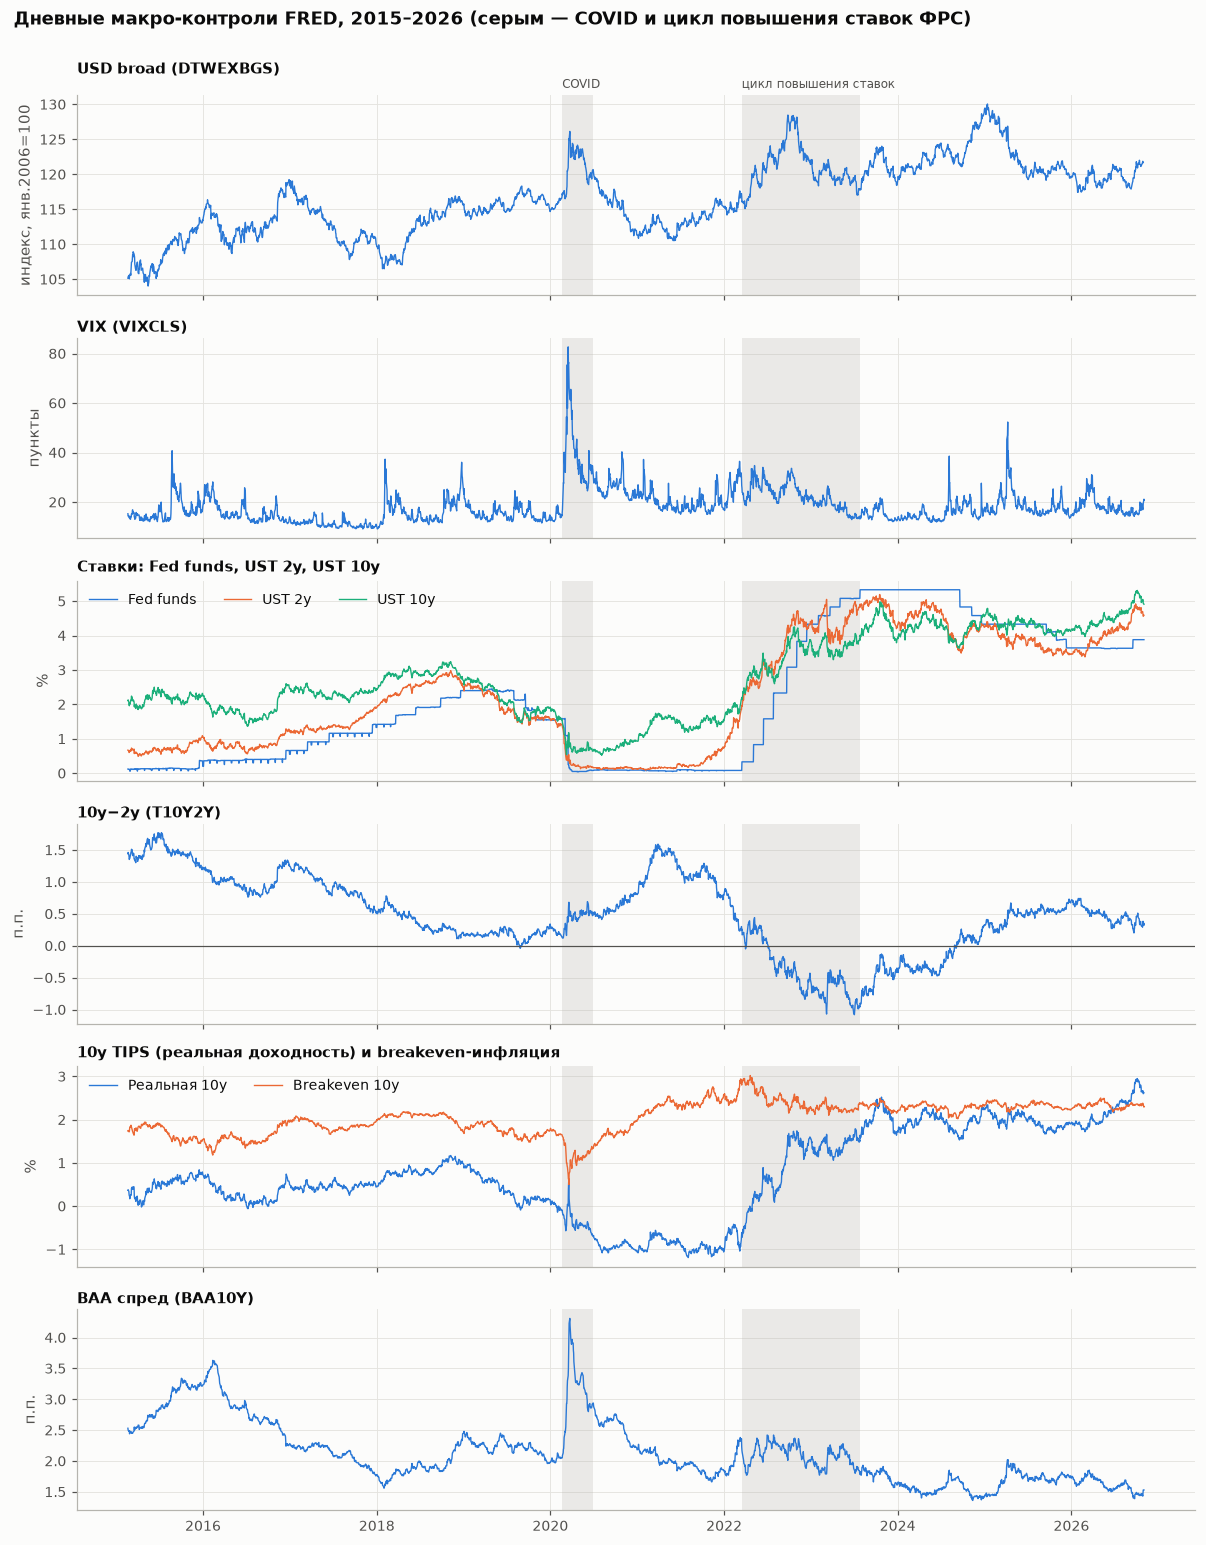

In [10]:
REGIMES = [("2020-02-20", "2020-06-30", "COVID"), ("2022-03-16", "2023-07-26", "цикл повышения ставок")]


def shade(ax, labels=False):
    for a, b, name in REGIMES:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=u.NEUTRAL, alpha=0.25, lw=0)
        if labels:
            ax.text(pd.Timestamp(a), 1.02, name, transform=ax.get_xaxis_transform(), fontsize=8,
                    color=u.INK_MUTED, va="bottom")


lv = d.set_index("date")
panels = [(["usd_broad"], "индекс, янв.2006=100"), (["vix"], "пункты"),
          (["fed_funds", "treasury_2y", "treasury_10y"], "%"), (["yield_curve_10y2y"], "п.п."),
          (["real_yield_10y", "breakeven_10y"], "%"), (["baa_spread"], "п.п.")]
fig, axes = plt.subplots(len(panels), 1, figsize=(11, 14), sharex=True)
for ax, (cols, unit) in zip(axes, panels):
    for i, c in enumerate(cols):
        s = lv[c].dropna()
        ax.plot(s.index, s.values, color=u.SERIES[i], lw=0.9, label=LABEL[c])
    shade(ax, labels=ax is axes[0])
    ax.set_ylabel(unit)
    if len(cols) > 1:
        ax.legend(loc="upper left", ncol=len(cols))
    else:
        ax.set_title(f"{LABEL[cols[0]]} ({SERIES_ID[cols[0]]})", fontsize=10, pad=14 if ax is axes[0] else 4)
axes[3].axhline(0, color=u.INK_MUTED, lw=0.8)
axes[2].set_title("Ставки: Fed funds, UST 2y, UST 10y", fontsize=10)
axes[4].set_title("10y TIPS (реальная доходность) и breakeven-инфляция", fontsize=10)
fig.suptitle("Дневные макро-контроли FRED, 2015–2026 (серым — COVID и цикл повышения ставок ФРС)",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

In [11]:
# Сводка уровней по режимам (средние)
periods = {"2015–2019": ("2015-02-19", "2019-12-31"), "COVID 20.02–30.06.2020": ("2020-02-20", "2020-06-30"),
           "2021": ("2021-01-01", "2021-12-31"), "повышение 16.03.22–26.07.23": ("2022-03-16", "2023-07-26"),
           "08.2023–11.2026": ("2023-07-27", "2026-11-03")}
reg_lv = pd.DataFrame({k: lv.loc[a:b, LEVELS].mean() for k, (a, b) in periods.items()}).round(2)
reg_lv = reg_lv.join(pd.DataFrame({"min": lv[LEVELS].min(), "дата min": lv[LEVELS].idxmin().dt.date,
                                   "max": lv[LEVELS].max(), "дата max": lv[LEVELS].idxmax().dt.date}))
reg_lv

,2015–2019,COVID 20.02–30.06.2020,2021,повышение 16.03.22–26.07.23,08.2023–11.2026,min,дата min,max,дата max
usd_broad,112.56,121.30,113.11,121.03,121.75,104.0202,2015-05-15,130.0413,2025-01-13
vix,15.04,39.52,19.66,22.40,17.21,9.1400,2017-11-03,82.6900,2020-03-16
fed_funds,1.13,0.31,0.08,3.22,4.51,0.0400,2020-04-23,5.3300,2023-07-27
treasury_2y,1.51,0.33,0.27,3.81,4.19,0.0900,2021-02-05,5.1900,2023-10-17
treasury_10y,2.28,0.78,1.45,3.40,4.34,0.5200,2020-08-04,5.3100,2026-10-05
yield_curve_10y2y,0.78,0.45,1.18,-0.41,0.15,-1.0800,2023-07-03,1.7700,2015-06-26
real_yield_10y,0.49,-0.37,-0.91,0.99,2.03,-1.1900,2021-08-03,2.9500,2026-10-05
breakeven_10y,1.79,1.15,2.36,2.41,2.31,0.5000,2020-03-19,3.0200,2022-04-21
baa_spread,2.39,3.19,1.95,2.09,1.64,1.3600,2024-11-12,4.3100,2020-03-23


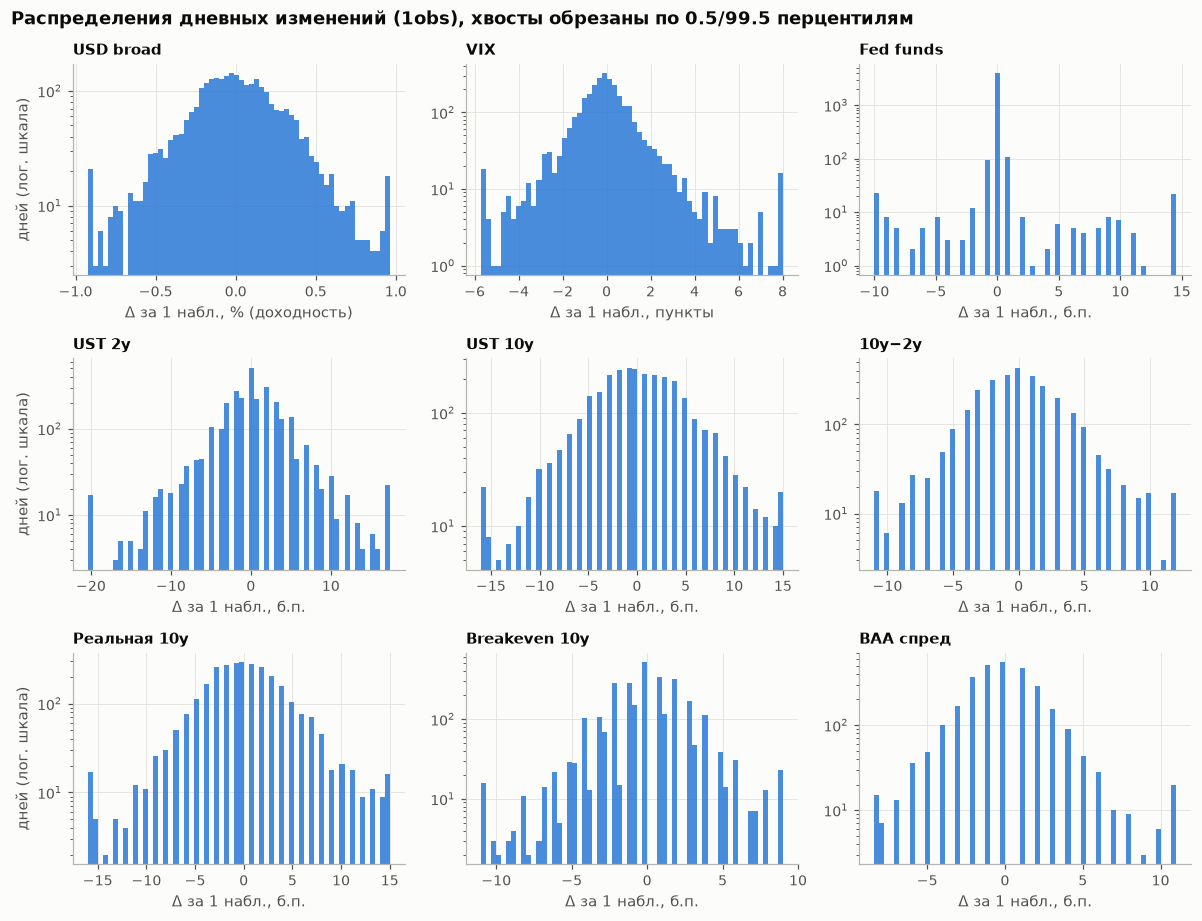

In [12]:
chg1 = d.set_index("date")[[CHG1[c] for c in LEVELS]]
chg1.columns = LEVELS
UNIT = {c: ("% (доходность)" if c == "usd_broad" else "пункты" if c == "vix" else "б.п.") for c in LEVELS}
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5))
for ax, c in zip(axes.ravel(), LEVELS):
    x = chg1[c].dropna()
    lo, hi = x.quantile([0.005, 0.995])
    ax.hist(x.clip(lo, hi), bins=60, color=u.SERIES[0], alpha=0.85)
    ax.set_yscale("log")
    ax.set_title(LABEL[c], fontsize=10)
    ax.set_xlabel(f"Δ за 1 набл., {UNIT[c]}")
for ax in axes[:, 0]:
    ax.set_ylabel("дней (лог. шкала)")
fig.suptitle("Распределения дневных изменений (1obs), хвосты обрезаны по 0.5/99.5 перцентилям",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [13]:
mom = []
for c in LEVELS:
    x = chg1[c].dropna()
    mom.append({"ряд": c, "ед.": UNIT[c], "N": len(x), "std": x.std(), "асимметрия": stats.skew(x),
                "экс. эксцесс": stats.kurtosis(x), "доля нулей": (x == 0).mean(),
                "q01": x.quantile(0.01), "q99": x.quantile(0.99),
                "max |Δ|": x.abs().max(), "дата max |Δ|": x.abs().idxmax().date()})
mom = pd.DataFrame(mom).set_index("ряд")
num = mom.select_dtypes("number").columns
mom[num] = mom[num].round(3)
mom

,ед.,N,std,асимметрия,экс. эксцесс,доля нулей,q01,q99,max |Δ|,дата max |Δ|
ряд,,,,,,,,,,
usd_broad,% (доходность),2918,0.322,0.048,2.790,0.000,-0.832,0.860,2.067,2016-03-17
vix,пункты,2977,1.916,2.117,31.983,0.004,-4.477,5.742,24.860,2020-03-16
fed_funds,б.п.,4274,3.758,4.931,247.435,0.919,-5.270,8.000,85.000,2020-03-16
treasury_2y,б.п.,2927,5.200,-0.695,9.942,0.173,-14.740,15.000,57.000,2023-03-13
treasury_10y,б.п.,2927,5.290,-0.052,1.883,0.083,-14.740,13.740,30.000,2022-11-10
yield_curve_10y2y,б.п.,2928,3.601,0.701,7.929,0.148,-9.000,10.000,42.000,2023-03-13
real_yield_10y,б.п.,2927,4.796,-0.085,6.900,0.099,-12.000,13.000,45.000,2020-03-20
breakeven_10y,б.п.,2928,3.004,-0.478,8.717,0.176,-8.000,8.000,32.000,2020-03-09
baa_spread,б.п.,2922,2.954,1.732,19.680,0.187,-7.000,8.000,38.000,2020-03-09


In [14]:
reg_std = pd.DataFrame({k: chg1.loc[a:b].std() for k, (a, b) in periods.items()}).round(2)
reg_std.insert(0, "ед.", [UNIT[c] for c in LEVELS])
reg_std

,ед.,2015–2019,COVID 20.02–30.06.2020,2021,повышение 16.03.22–26.07.23,08.2023–11.2026
usd_broad,% (доходность),0.31,0.53,0.26,0.38,0.30
vix,пункты,1.56,5.55,2.11,1.42,1.79
fed_funds,б.п.,2.76,8.58,0.46,7.71,2.40
treasury_2y,б.п.,3.39,4.87,2.35,9.59,5.73
treasury_10y,б.п.,4.25,7.86,4.28,7.85,5.50
yield_curve_10y2y,б.п.,2.65,4.95,3.68,5.66,3.62
real_yield_10y,б.п.,3.57,8.76,4.08,7.59,4.60
breakeven_10y,б.п.,2.35,7.00,3.04,4.40,2.28
baa_spread,б.п.,2.11,8.32,2.20,4.16,2.46


**Вывод.** Режимы видны хорошо. В COVID VIX доходил до 82.69 (2020-03-16), BAA-спред — до 4.31 п.п. (2020-03-23), breakeven падал до 0.50% (2020-03-19). В цикле повышения ставок fed funds вырос с 0.04% (2020-04-23) до 5.33% (2023-07-27), кривая 10y−2y ушла в инверсию до −1.08 п.п. (2023-07-03). Реальная доходность 10y выросла с −1.19% (2021-08-03) до 2.95% (2026-10-05), UST 10y обновил максимум выборки 5.31% тоже 2026-10-05. Дневные изменения тяжелохвостые: избыточный эксцесс у VIX 32, у BAA 19.7, у 2y 9.9, у breakeven 8.7, у USD 2.8. Волатильность сильно зависит от режима: std ΔVIX 1.56 п. в 2015–2019 против 5.55 в COVID, std Δ2y 3.4 б.п. против 9.6 б.п. в цикле повышения. Fed funds не меняется в 92% дней (эксцесс 247), поэтому как дневной контроль он почти неинформативен.

## 3. Стационарность: уровни против изменений (ADF)

ADF с константой, лаги по AIC; ряды без NA (рабочие дни ряда).

In [15]:
adf_rows = []
for c in LEVELS:
    s = lv[c].dropna()
    for kind, x in (("уровень", s), ("Δ 1obs", chg1[c].dropna())):
        stat, p, lags, nobs, *_ = adfuller(x.to_numpy(), regression="c", autolag="AIC", result_object=False)
        adf_rows.append({"ряд": c, "тип": kind, "ADF": round(stat, 2), "p-value": round(p, 4),
                         "лагов": lags, "N": nobs})
adf = pd.DataFrame(adf_rows).pivot(index="ряд", columns="тип", values=["ADF", "p-value"]).loc[LEVELS]
adf

ADF         p-value        
тип               Δ 1obs уровень  Δ 1obs уровень
ряд                                             
usd_broad         -51.72   -2.54     0.0  0.1060
vix               -20.10   -5.90     0.0  0.0000
fed_funds         -17.59   -0.79     0.0  0.8222
treasury_2y       -13.65   -0.62     0.0  0.8653
treasury_10y      -40.48   -0.50     0.0  0.8921
yield_curve_10y2y -10.63   -1.87     0.0  0.3457
real_yield_10y    -40.76   -0.55     0.0  0.8813
breakeven_10y     -14.11   -2.10     0.0  0.2430
baa_spread        -11.63   -2.08     0.0  0.2525

**Вывод.** Единичный корень на уровнях отвергается только у VIX (ADF −5.90, p < 0.0001), то есть VIX возвращается к среднему. Для USD (p = 0.106), breakeven (0.24), BAA (0.25), 10y−2y (0.35) и ставок (0.82–0.89) он не отвергается. Для всех изменений p ≈ 0 (ADF от −10.6 до −51.7). Вывод для модели: брать изменения. Уровень допустим только у VIX как индикатор режима риска; уровни ставок и USD дадут ложные связи с трендом.

## 4. Дневные связи с WTI: доходность F1 и Δ(F1−F2)

Строим панель на торговых днях WTI, уровни FRED присоединяем по дате **без заполнения**, изменения считаем
между соседними торговыми днями только там, где ряд наблюдается в обе даты (одинаковое окно у WTI и контроля).
Оговорки: (1) у Barchart «Daily Nearby» нет идентификатора контракта, поэтому доходность F1 и Δ(F1−F2)
в дни ролла содержат скачок смены контракта (вероятный пример — Δспреда = +3.37 $ 2020-04-15, спред скачком с −7.29 до −3.92); (2) время фиксации разное:
WTI — сеттлмент 14:30 ET, USD broad — полуденные курсы ФРС NY, ставки/VIX — около закрытия; поэтому смотрим
также лаги ±1 день и ранговую корреляцию Спирмена.

In [16]:
cv = curve.rename(columns={"trading_day": "date"})[["date", "wti_f1", "wti_f2", "spread_f1_f2"]]
cv = cv.astype({"wti_f1": float, "wti_f2": float, "spread_f1_f2": float})
panel = cv.merge(d[["date"] + LEVELS], on="date", how="left")
panel = panel[panel["date"] >= d["date"].min()].reset_index(drop=True)
MACRO = ["usd_broad", "vix", "treasury_2y", "treasury_10y", "yield_curve_10y2y", "real_yield_10y",
         "breakeven_10y", "baa_spread"]


def changes(frame: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame({"date": frame["date"]})
    out["usd_broad"] = frame["usd_broad"].pct_change(fill_method=None) * 100
    out["vix"] = frame["vix"].diff()
    for c in MACRO[2:] + ["fed_funds"]:
        if c in frame:
            out[c] = frame[c].diff() * 100
    return out


pc = changes(panel)
pc["wti_ret"] = np.log(panel["wti_f1"]).diff() * 100
pc["d_spread"] = panel["spread_f1_f2"].diff()
pc = pc.set_index("date")
print("торговых дней WTI в окне FRED:", len(panel), "| из них FRED (UST 10y) не наблюдается:",
      int(panel["treasury_10y"].isna().sum()))
print("самые большие |доходности F1|, %:")
print(pc["wti_ret"].abs().nlargest(5).round(1))

торговых дней WTI в окне FRED: 2949 | из них FRED (UST 10y) не наблюдается: 25
самые большие |доходности F1|, %:
date
2020-04-21    56.9
2020-04-30    37.2
2020-03-09    28.2
2020-04-27    28.2
2020-03-18    27.2
Name: wti_ret, dtype: float64


In [17]:
covid = (pc.index >= "2020-03-01") & (pc.index <= "2020-05-31")
corr_rows = []
for tgt in ("wti_ret", "d_spread"):
    for c in MACRO:
        x = pc[[tgt, c]].dropna()
        xc = x[~((x.index >= "2020-03-01") & (x.index <= "2020-05-31"))]
        pre, y26 = x[x.index < "2026-01-01"], x[x.index >= "2026-01-01"]
        corr_rows.append({"цель": tgt, "контроль": c, "N": len(x),
                          "Пирсон": x[tgt].corr(x[c]), "Спирмен": x[tgt].corr(x[c], method="spearman"),
                          "Пирсон без 03–05.2020": xc[tgt].corr(xc[c]),
                          "Спирмен до 2026": pre[tgt].corr(pre[c], method="spearman"),
                          "Спирмен 2026": y26[tgt].corr(y26[c], method="spearman")})
corr_d = pd.DataFrame(corr_rows)
print("порог |r| для p<0.05 при N≈2900:", round(1.96 / np.sqrt(2900), 3))
print("N в 2026:", int((pc.index >= "2026-01-01").sum()))
corr_d.round(3).pivot(index="контроль", columns="цель",
                      values=["Пирсон", "Спирмен", "Пирсон без 03–05.2020", "Спирмен до 2026", "Спирмен 2026"]).loc[MACRO]

порог |r| для p<0.05 при N≈2900: 0.036
N в 2026: 213


Пирсон          Спирмен         Пирсон без 03–05.2020         Спирмен до 2026         Спирмен 2026        
цель              d_spread wti_ret d_spread wti_ret              d_spread wti_ret        d_spread wti_ret     d_spread wti_ret
контроль                                                                                                                      
usd_broad            0.072  -0.123   -0.001  -0.158                 0.065  -0.132          -0.016  -0.195        0.172   0.301
vix                  0.038  -0.169    0.029  -0.139                 0.043  -0.159           0.008  -0.188        0.188   0.383
treasury_2y          0.032   0.126    0.044   0.162                 0.036   0.157           0.021   0.148        0.224   0.323
treasury_10y         0.037   0.171    0.071   0.212                 0.052   0.211           0.049   0.196        0.286   0.419
yield_curve_10y2y    0.008   0.069    0.037   0.089                 0.023   0.076           0.036   0.091        0.059   0.063
real_yield_10y       0.004   0.014    0.012   0.046                -0.002   0.018          -0.004   0.032        0.150   0.219
breakeven_10y        0.057   0.277    0.116   0.344                 0.100   0.361           0.106   0.337        0.265   0.470
baa_spread           0.013  -0.140    0.000  -0.081                 0.017  -0.095           0.010  -0.085       -0.085  -0.062

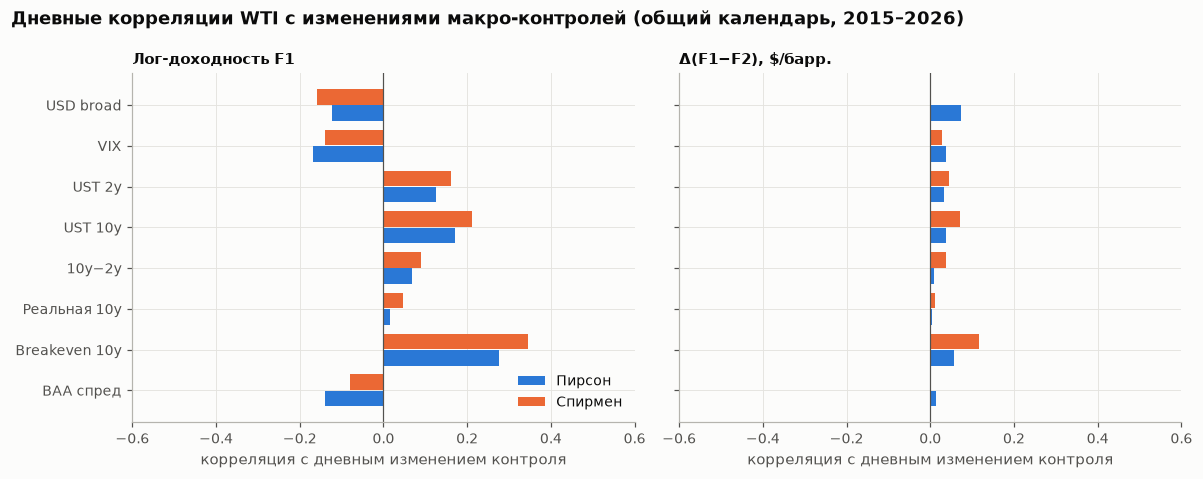

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ypos = np.arange(len(MACRO))
for ax, tgt, title in zip(axes, ("wti_ret", "d_spread"), ("Лог-доходность F1", "Δ(F1−F2), $/барр.")):
    sub = corr_d[corr_d["цель"] == tgt].set_index("контроль").loc[MACRO]
    ax.barh(ypos + 0.2, sub["Пирсон"], height=0.38, color=u.SERIES[0], label="Пирсон")
    ax.barh(ypos - 0.2, sub["Спирмен"], height=0.38, color=u.SERIES[1], label="Спирмен")
    ax.axvline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("корреляция с дневным изменением контроля")
    ax.set_xlim(-0.6, 0.6)
axes[0].set_yticks(ypos, [LABEL[c] for c in MACRO])
axes[0].invert_yaxis()
axes[0].legend(loc="lower right")
fig.suptitle("Дневные корреляции WTI с изменениями макро-контролей (общий календарь, 2015–2026)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [19]:
# Лаги: corr(WTI_t, Δконтроль_{t+k}); k=+1 — контроль на следующий день (эффект разного времени фиксации)
lag_rows = []
for tgt in ("wti_ret", "d_spread"):
    for c in MACRO:
        lag_rows.append({"цель": tgt, "контроль": c,
                         **{f"k={k:+d}": pc[tgt].corr(pc[c].shift(-k), method="spearman") for k in (-1, 0, 1)}})
pd.DataFrame(lag_rows).set_index(["цель", "контроль"]).round(3)

k=-1   k=+0   k=+1
цель     контроль                              
wti_ret  usd_broad         -0.011 -0.158 -0.020
         vix                0.006 -0.139  0.014
         treasury_2y       -0.004  0.162  0.017
         treasury_10y       0.007  0.212  0.022
         yield_curve_10y2y  0.006  0.089  0.005
         real_yield_10y    -0.014  0.046 -0.014
         breakeven_10y      0.035  0.344  0.046
         baa_spread        -0.029 -0.081 -0.082
d_spread usd_broad          0.026 -0.001 -0.052
         vix                0.044  0.029 -0.052
         treasury_2y       -0.001  0.044 -0.000
         treasury_10y       0.007  0.071  0.013
         yield_curve_10y2y  0.002  0.037  0.028
         real_yield_10y     0.004  0.012 -0.002
         breakeven_10y      0.009  0.116  0.014
         baa_spread         0.009  0.000 -0.011

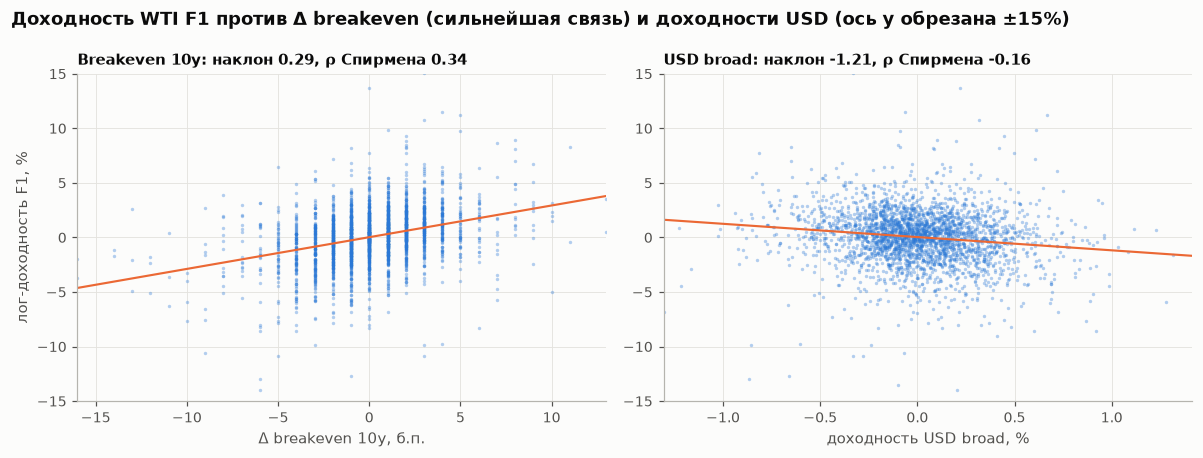

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, c, xl in ((axes[0], "breakeven_10y", "Δ breakeven 10y, б.п."), (axes[1], "usd_broad", "доходность USD broad, %")):
    x = pc[["wti_ret", c]].dropna()
    ax.scatter(x[c], x["wti_ret"], s=5, alpha=0.35, color=u.SERIES[0], lw=0)
    b = np.polyfit(x[c], x["wti_ret"], 1)
    xs = np.linspace(x[c].quantile(0.001), x[c].quantile(0.999), 50)
    ax.plot(xs, np.polyval(b, xs), color=u.SERIES[1], lw=1.4)
    ax.set_xlim(x[c].quantile(0.001), x[c].quantile(0.999))
    ax.set_ylim(-15, 15)
    ax.set_xlabel(xl)
    ax.set_title(f"{LABEL[c]}: наклон {b[0]:.2f}, ρ Спирмена {x['wti_ret'].corr(x[c], method='spearman'):.2f}",
                 fontsize=10)
axes[0].set_ylabel("лог-доходность F1, %")
fig.suptitle("Доходность WTI F1 против Δ breakeven (сильнейшая связь) и доходности USD (ось y обрезана ±15%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

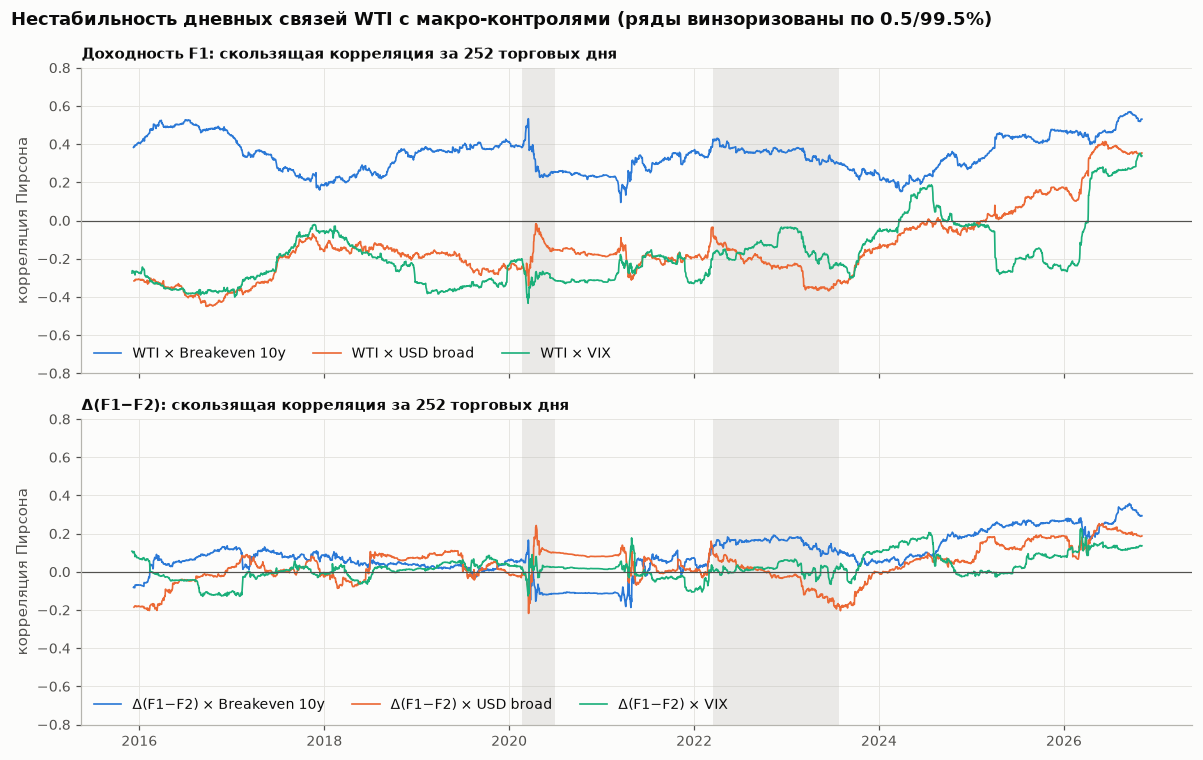

In [21]:
PAIRS = [("wti_ret", "breakeven_10y"), ("wti_ret", "usd_broad"), ("wti_ret", "vix")]
# Пирсон в скользящем окне неустойчив к выбросам апреля 2020 (|доходность F1| до 57%) — винзоризуем по 0.5/99.5%
pw = pc.apply(lambda s: s.clip(*s.quantile([0.005, 0.995])))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for i, (tgt, c) in enumerate(PAIRS):
    r = pw[tgt].rolling(252, min_periods=200).corr(pw[c])
    axes[0].plot(r.index, r.values, color=u.SERIES[i], lw=1.1, label=f"WTI × {LABEL[c]}")
for i, c in enumerate(["breakeven_10y", "usd_broad", "vix"]):
    r = pw["d_spread"].rolling(252, min_periods=200).corr(pw[c])
    axes[1].plot(r.index, r.values, color=u.SERIES[i], lw=1.1, label=f"Δ(F1−F2) × {LABEL[c]}")
for ax, t in zip(axes, ("Доходность F1", "Δ(F1−F2)")):
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    shade(ax)
    ax.set_ylabel("корреляция Пирсона")
    ax.set_title(f"{t}: скользящая корреляция за 252 торговых дня", fontsize=10)
    ax.legend(loc="lower left", ncol=3)
    ax.set_ylim(-0.8, 0.8)
fig.suptitle("Нестабильность дневных связей WTI с макро-контролями (ряды винзоризованы по 0.5/99.5%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [22]:
roll_stats = {}
for tgt, c in PAIRS + [("d_spread", "breakeven_10y"), ("d_spread", "usd_broad"), ("d_spread", "vix")]:
    r = pw[tgt].rolling(252, min_periods=200).corr(pw[c]).dropna()
    roll_stats[f"{tgt} × {c}"] = {"min": r.min(), "медиана": r.median(), "max": r.max(),
                                  "доля окон с r>0": (r > 0).mean(), "дата min": r.idxmin().date(),
                                  "дата max": r.idxmax().date()}
rs = pd.DataFrame(roll_stats).T
rs[["min", "медиана", "max", "доля окон с r>0"]] = rs[["min", "медиана", "max", "доля окон с r>0"]].astype(float).round(2)
rs

,min,медиана,max,доля окон с r>0,дата min,дата max
wti_ret × breakeven_10y,0.09,0.35,0.57,1.00,2021-03-17,2026-09-18
wti_ret × usd_broad,-0.45,-0.17,0.41,0.16,2016-09-23,2026-06-12
wti_ret × vix,-0.43,-0.21,0.35,0.10,2020-03-16,2026-10-30
d_spread × breakeven_10y,-0.19,0.08,0.36,0.87,2021-04-26,2026-09-16
d_spread × usd_broad,-0.22,0.04,0.25,0.67,2020-03-18,2026-06-01
d_spread × vix,-0.13,0.02,0.23,0.65,2016-09-08,2026-03-09


In [23]:
# Контекст режима 2026: уровень F1 и спред F1−F2 по кварталам
cv.set_index("date")[["wti_f1", "spread_f1_f2"]].loc["2025":].resample("QE").agg(["mean", "min", "max"]).round(2)

wti_f1                spread_f1_f2             
             mean    min     max         mean   min    max
date                                                      
2025-03-31  71.26  66.03   78.71         0.51  0.15   1.47
2025-06-30  63.40  57.13   73.84         0.79  0.26   1.83
2025-09-30  64.67  61.77   70.00         0.72  0.23   1.44
2025-12-31  59.03  55.13   62.02         0.23  0.03   0.63
2026-03-31  72.60  55.99  102.88         1.22  0.09   8.22
2026-06-30  91.85  69.23  112.95         3.92  0.23  13.94
2026-09-30  85.10  68.55  102.48         2.17 -0.01   5.24
2026-12-31  95.66  88.12  104.12         1.51  0.73   2.33

**Вывод.** Порог значимости |r| ≈ 0.036 при N ≈ 2900. Дневная доходность WTI F1 сильнее всего связана с Δbreakeven 10y (Пирсон 0.28, Спирмен 0.34), дальше идут UST 10y (0.17/0.21), 2y (0.13/0.16), VIX (−0.17/−0.14), USD (−0.12/−0.16) и BAA (−0.14/−0.08). С реальной доходностью связи практически нет (0.01/0.05), так что связь с 10y идёт через breakeven. Breakeven сам частично определяется нефтью, поэтому как одновременный контроль он «съедает» нефтяной сигнал.

Δ(F1−F2) связан с макро слабо: максимум у breakeven (0.06/0.12), у остальных |ρ| ≤ 0.07. У USD Пирсон 0.072 при Спирмене −0.001, то есть Пирсона создают выбросы.

Лаги ±1 день почти нулевые (|ρ| ≤ 0.05), гипотеза о сдвиге из-за полуденной фиксации USD не подтвердилась. Исключение — BAA: ρ при k = +1 (−0.082) равен одновременному (−0.081), BAA10Y частично запаздывает на день.

Связи нестабильны (скользящее окно, винзоризация 0.5/99.5%). WTI × breakeven везде положителен (от 0.09 до 0.57, медиана 0.35). WTI × USD колеблется от −0.45 до +0.41 (положителен в 16% окон), WTI × VIX — от −0.43 до +0.35. Обе связи с 2025 года сползают к нулю и в 2026 становятся положительными: Спирмен в 2026 году +0.30 и +0.38 против −0.20 и −0.19 до 2026. Это режим ценового шока 2026 года: F1 вырос со средних $59 в IV кв. 2025 до максимума $112.95 во II кв. 2026, спред F1−F2 доходил до $13.94. В этом режиме и Δ(F1−F2) начал коррелировать с макро (ρ до 0.29 с UST 10y).

## 5. Недельный вид, выровненный по релизам EIA

Для каждого релиза R берём значение контроля на последний день наблюдения ≤ R−1 (день до релиза) и на
последний день ≤ R−8; изменение между ними — «макро-неделя до релиза». Это информация, существовавшая до релиза
(с оговоркой о публикационных лагах — ниже). Цели: `surprise_mmbbl` и Δ(F1−F2) в день релиза
(спред в день R минус спред предыдущего торгового дня).

In [24]:
r_ = rel[rel["release_date"] >= d["date"].min() + pd.Timedelta(days=8)].copy().reset_index(drop=True)
t_end = r_["release_date"] - pd.Timedelta(days=1)
t_start = r_["release_date"] - pd.Timedelta(days=8)


def asof(col: str, t: pd.Series) -> pd.DataFrame:
    s = d[["date", col]].dropna()
    return pd.merge_asof(pd.DataFrame({"t": t.to_numpy()}), s, left_on="t", right_on="date", direction="backward")


wkly = pd.DataFrame({"release_date": r_["release_date"]})
stale = {}
for c in LEVELS:
    e, s0 = asof(c, t_end), asof(c, t_start)
    if c == "usd_broad":
        wkly[c] = (e[c] / s0[c] - 1) * 100
    elif c == "vix":
        wkly[c] = e[c] - s0[c]
    else:
        wkly[c] = (e[c] - s0[c]) * 100
    stale[c] = (e["t"] - e["date"]).dt.days
spread = cv.set_index("date")["spread_f1_f2"]
wkly["d_spread_release"] = r_["release_date"].map(spread.diff()).to_numpy()
wkly["surprise_mmbbl"] = r_["surprise_mmbbl"].to_numpy()
wkly["wti_ret_release"] = r_["release_date"].map(np.log(cv.set_index("date")["wti_f1"]).diff() * 100).to_numpy()
print("релизов:", len(wkly), "| с Δспреда в день релиза:", wkly["d_spread_release"].notna().sum(),
      "| с surprise:", wkly["surprise_mmbbl"].notna().sum())
print("Сколько дней между R−1 и датой использованного наблюдения (в текущем файле):")
pd.DataFrame({c: stale[c].value_counts().sort_index() for c in LEVELS}).fillna(0).astype(int)

релизов: 608 | с Δспреда в день релиза: 608 | с surprise: 608
Сколько дней между R−1 и датой использованного наблюдения (в текущем файле):


,usd_broad,vix,fed_funds,treasury_2y,treasury_10y,yield_curve_10y2y,real_yield_10y,breakeven_10y,baa_spread
0,598,604,607,600,600,601,600,601,600
1,7,3,1,7,7,6,7,6,7
2,1,1,0,1,1,1,1,1,1
4,1,0,0,0,0,0,0,0,0
5,1,0,0,0,0,0,0,0,0


In [25]:
wk_rows = []
for tgt in ("surprise_mmbbl", "d_spread_release"):
    for c in MACRO + ["fed_funds"]:
        x = wkly[[tgt, c]].dropna()
        r, p = stats.pearsonr(x[c], x[tgt])
        rho, p_s = stats.spearmanr(x[c], x[tgt])
        wk_rows.append({"цель": tgt, "контроль": c, "N": len(x), "Пирсон": r, "p": p, "Спирмен": rho, "p (Спирмен)": p_s})
wk_corr = pd.DataFrame(wk_rows)
x = wkly[["surprise_mmbbl", "d_spread_release"]].dropna()
print("Ориентир: corr(surprise, Δспреда в день релиза) =",
      round(x["surprise_mmbbl"].corr(x["d_spread_release"]), 3), "Спирмен",
      round(x["surprise_mmbbl"].corr(x["d_spread_release"], method="spearman"), 3), "N =", len(x))
y = wkly[["surprise_mmbbl", "wti_ret_release"]].dropna()
print("Ориентир: corr(surprise, доходность F1 в день релиза) =", round(y["surprise_mmbbl"].corr(y["wti_ret_release"]), 3),
      "Спирмен", round(y["surprise_mmbbl"].corr(y["wti_ret_release"], method="spearman"), 3), "N =", len(y))
print("порог |r| для p<0.05 при N≈600:", round(1.96 / np.sqrt(600), 3), "| тестов: ", len(wk_corr))
wk_corr.round(3).set_index(["цель", "контроль"])

Ориентир: corr(surprise, Δспреда в день релиза) = 0.01 Спирмен -0.061 N = 608
Ориентир: corr(surprise, доходность F1 в день релиза) = -0.081 Спирмен -0.149 N = 608
порог |r| для p<0.05 при N≈600: 0.08 | тестов:  18


N  Пирсон      p  Спирмен  p (Спирмен)
цель             контроль                                                   
surprise_mmbbl   usd_broad          608   0.017  0.673    0.018        0.656
                 vix                608  -0.017  0.684   -0.001        0.989
                 treasury_2y        608   0.024  0.560    0.041        0.315
                 treasury_10y       608   0.034  0.408    0.043        0.286
                 yield_curve_10y2y  608   0.015  0.712   -0.003        0.932
                 real_yield_10y     608   0.049  0.230    0.057        0.161
                 breakeven_10y      608  -0.021  0.605   -0.020        0.618
                 baa_spread         608  -0.021  0.601    0.003        0.951
                 fed_funds          608  -0.001  0.980    0.003        0.946
d_spread_release usd_broad          608  -0.015  0.705   -0.032        0.437
                 vix                608  -0.057  0.159    0.012        0.770
                 treasury_2y        608  -0.042  0.299   -0.014        0.739
                 treasury_10y       608  -0.003  0.947    0.036        0.381
                 yield_curve_10y2y  608   0.059  0.147    0.081        0.046
                 real_yield_10y     608  -0.003  0.940    0.024        0.552
                 breakeven_10y      608   0.000  0.998    0.001        0.989
                 baa_spread         608  -0.104  0.010   -0.011        0.790
                 fed_funds          608   0.029  0.471    0.023        0.578

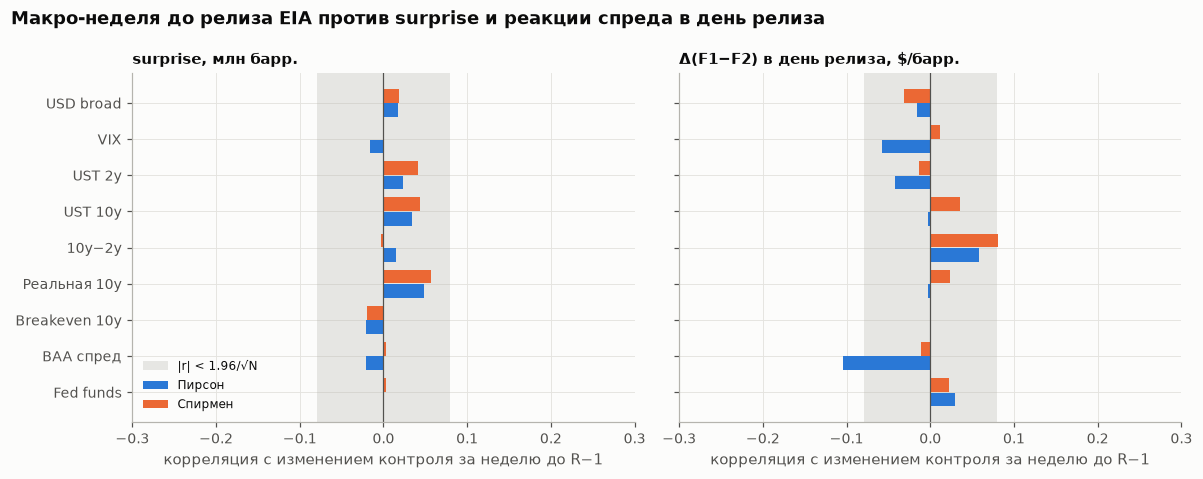

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
cols_w = MACRO + ["fed_funds"]
ypos = np.arange(len(cols_w))
for ax, tgt, title in zip(axes, ("surprise_mmbbl", "d_spread_release"),
                          ("surprise, млн барр.", "Δ(F1−F2) в день релиза, $/барр.")):
    sub = wk_corr[wk_corr["цель"] == tgt].set_index("контроль").loc[cols_w]
    band = 1.96 / np.sqrt(sub["N"].median())
    ax.axvspan(-band, band, color=u.NEUTRAL, alpha=0.3, lw=0, label="|r| < 1.96/√N")
    ax.barh(ypos + 0.2, sub["Пирсон"], height=0.38, color=u.SERIES[0], label="Пирсон")
    ax.barh(ypos - 0.2, sub["Спирмен"], height=0.38, color=u.SERIES[1], label="Спирмен")
    ax.axvline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_xlim(-0.3, 0.3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("корреляция с изменением контроля за неделю до R−1")
axes[0].set_yticks(ypos, [LABEL[c] for c in cols_w])
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Макро-неделя до релиза EIA против surprise и реакции спреда в день релиза",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Публикационные лаги дневных рядов (по снимку метаданных из ноутбука сбора: последняя дата наблюдения против
времени последнего обновления). Исторический файл содержит значения за каждый день, но в реальном времени
часть из них к утру среды ещё не опубликована.

In [27]:
pub = meta[["name", "series_id", "frequency", "observation_end", "last_updated"]].iloc[:9].copy()
pub["obs_end"] = pd.to_datetime(pub["observation_end"])
pub["updated_local"] = pd.to_datetime(pub["last_updated"].str[:19])
pub["лаг, дн. (снимок)"] = (pub["updated_local"].dt.normalize() - pub["obs_end"]).dt.days
pub[["name", "series_id", "frequency", "observation_end", "last_updated", "лаг, дн. (снимок)"]]

,name,series_id,frequency,observation_end,last_updated,"лаг, дн. (снимок)"
0,usd_broad,DTWEXBGS,Daily,2026-10-30,2026-11-02 15:51:35-06,3
1,vix,VIXCLS,"Daily, Close",2026-11-03,2026-11-04 08:37:31-06,1
2,fed_funds,DFF,"Daily, 7-Day",2026-11-02,2026-11-03 15:16:31-06,1
3,treasury_2y,DGS2,Daily,2026-11-02,2026-11-03 15:16:27-06,1
4,treasury_10y,DGS10,Daily,2026-11-02,2026-11-03 15:16:31-06,1
5,yield_curve_10y2y,T10Y2Y,Daily,2026-11-03,2026-11-03 16:02:33-06,0
6,real_yield_10y,DFII10,Daily,2026-11-02,2026-11-03 15:16:27-06,1
7,breakeven_10y,T10YIE,Daily,2026-11-03,2026-11-03 16:03:26-06,0
8,baa_spread,BAA10Y,Daily,2026-11-02,2026-11-03 16:02:32-06,1


**Вывод.** Изменения макро за неделю до релиза **не связаны с surprise**: у всех 9 контролей |r| ≤ 0.05 (Спирмен ≤ 0.06), p ≥ 0.16. Это ожидаемо: FRED-контроли объясняют цену, а не запасы. С Δ(F1−F2) в день релиза формально значимы два теста из 18. BAA по Пирсону −0.10 (p = 0.01), но по Спирмену −0.01, то есть это выброс. 10y−2y по Спирмену 0.08 (p = 0.046) — при 18 тестах одна такая находка ожидается случайно.

Важная побочная находка: даже сам surprise почти не связан с Δ(F1−F2) в день релиза (r = 0.01, Спирмен −0.06). С доходностью F1 в тот же день связь заметнее (−0.08/−0.15). Изменение спреда от закрытия до закрытия — шумная мера реакции (роллы, прочие новости дня).

В текущем файле срез на R−1 совпадает с датой R−1 у 598–607 из 608 релизов. Но по метаданным в реальном времени к среде 10:30 ET известно не всё: DTWEXBGS публикуется раз в неделю (по пятницу 2026-10-30 — в понедельник 2026-11-02). DGS2, DGS10, DFII10, BAA10Y и DFF выходят на следующий день около 16:15 ET, то есть значение за вторник появляется уже после релиза. VIX выходит утром следующего дня (09:37 ET), T10Y2Y и T10YIE — в тот же день. Эти времена взяты из одного снимка метаданных.

## 6. Месячные макро-ряды: тренды, лаг публикации, ревизии

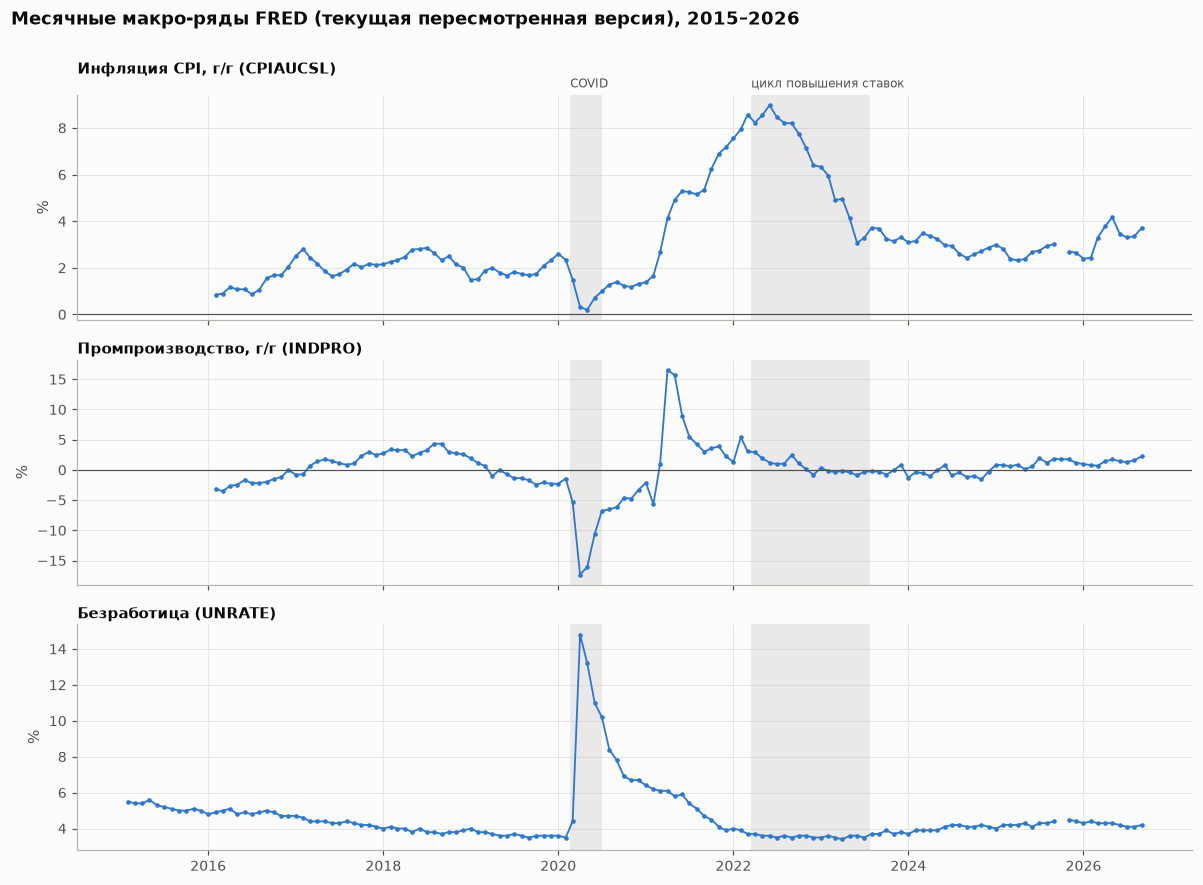

In [28]:
m = monthly.set_index("date")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (c, t, unit) in zip(axes, [("cpi_yoy_pct", "Инфляция CPI, г/г (CPIAUCSL)", "%"),
                                   ("industrial_production_yoy_pct", "Промпроизводство, г/г (INDPRO)", "%"),
                                   ("unemployment", "Безработица (UNRATE)", "%")]):
    s = m[c]
    ax.plot(s.index, s.values, color=u.SERIES[0], lw=1.2, marker="o", ms=2)
    shade(ax, labels=ax is axes[0])
    if c != "unemployment":
        ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_ylabel(unit)
    ax.set_title(t, fontsize=10, pad=14 if ax is axes[0] else 4)
fig.suptitle("Месячные макро-ряды FRED (текущая пересмотренная версия), 2015–2026",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

In [29]:
print("NA в месячном файле:")
print(monthly.set_index("date").isna().sum().to_string())
print("\nмесяцы с NA в уровнях:", monthly.loc[monthly[["cpi", "industrial_production", "unemployment"]].isna().any(axis=1),
                                             "date"].dt.date.tolist())
summary_m = pd.DataFrame({c: {"min": m[c].min(), "дата min": m[c].idxmin().date(), "max": m[c].max(),
                              "дата max": m[c].idxmax().date(), "последнее": m[c].dropna().iloc[-1],
                              "месяц посл.": m[c].dropna().index[-1].date()}
                          for c in ["cpi_yoy_pct", "industrial_production_yoy_pct", "unemployment"]}).T
summary_m

NA в месячном файле:
cpi                               1
industrial_production             0
unemployment                      1
cpi_yoy_pct                      13
industrial_production_yoy_pct    12
unemployment_change_1m_pp         3

месяцы с NA в уровнях: [datetime.date(2025, 10, 1)]


,min,дата min,max,дата max,последнее,месяц посл.
cpi_yoy_pct,0.198201,2020-05-01,8.979361,2022-06-01,3.717251,2026-09-01
industrial_production_yoy_pct,-17.318282,2020-04-01,16.552135,2021-04-01,2.245151,2026-09-01
unemployment,3.4,2023-04-01,14.8,2020-04-01,4.2,2026-09-01


Лаг публикации и ревизии. Файлы с первыми публикациями (`output_type=4`) на этой машине нет, поэтому используем
то, что сохранено в выходах ноутбука сбора: статистику лага `realtime_start − date` и две выдержки
initial-release (CPI 2015-02…2016-04 и UNRATE 2025-02…2026-09), и сравниваем их с текущей версией.

In [30]:
lag_stats = nb02_table('monthly_initial["availability_lag_days"]')
print("Лаг первой публикации, дней от первого числа месяца наблюдения (ноутбук 02):")
print(lag_stats.round(1).to_string())
init_head = nb02_table("monthly_initial = client.fetch_many_long")
init_tail = nb02_table('monthly_initial[\n')
init = pd.concat([init_head, init_tail], ignore_index=True)[["name", "date", "value", "realtime_start", "realtime_end"]]
init["date"] = pd.to_datetime(init["date"])
cur_long = monthly.melt(id_vars="date", value_vars=["cpi", "industrial_production", "unemployment"],
                        var_name="name", value_name="current")
rev = init.merge(cur_long, on=["name", "date"], how="left")
rev["ревизия (тек. − перв.)"] = rev["current"] - rev["value"]
rev["ревизия, %"] = rev["ревизия (тек. − перв.)"] / rev["value"] * 100
rev = rev.rename(columns={"value": "первая публикация", "current": "текущая"})
rev.round({"первая публикация": 3, "текущая": 3, "ревизия (тек. − перв.)": 3, "ревизия, %": 3})

Лаг первой публикации, дней от первого числа месяца наблюдения (ноутбук 02):
                       count  mean  std   min   25%   50%   75%   max
cpi                    140.0  42.7  4.1  37.0  40.0  42.0  44.0  78.0
industrial_production  140.0  46.0  5.3  42.0  44.0  45.0  46.0  93.0
unemployment           140.0  35.0  5.7  31.0  32.0  34.0  36.0  80.0


,name,date,первая публикация,realtime_start,realtime_end,текущая,ревизия (тек. − перв.),"ревизия, %"
0,cpi,2015-02-01,235.186,2015-03-24,2016-02-18,235.342,0.156,0.066
1,cpi,2015-03-01,235.740,2015-04-17,2016-02-18,235.976,0.236,0.100
2,cpi,2015-04-01,235.982,2015-05-22,2016-02-18,236.222,0.240,0.102
3,cpi,2015-05-01,237.031,2015-06-18,2016-02-18,237.001,-0.030,-0.013
4,cpi,2015-06-01,237.786,2015-07-17,2016-02-18,237.657,-0.129,-0.054
5,cpi,2015-07-01,238.099,2015-08-19,2016-02-18,238.034,-0.065,-0.027
6,cpi,2015-08-01,237.931,2015-09-16,2016-02-18,238.033,0.102,0.043
7,cpi,2015-09-01,237.566,2015-10-15,2016-02-18,237.498,-0.068,-0.029
8,cpi,2015-10-01,238.042,2015-11-17,2016-02-18,237.733,-0.309,-0.130
9,cpi,2015-11-01,238.111,2015-12-15,2016-02-18,238.017,-0.094,-0.039


In [31]:
rv = rev.dropna(subset=["ревизия (тек. − перв.)"])
print(rv.groupby("name")["ревизия (тек. − перв.)"].agg(N="size", ненулевых=lambda s: (s.round(6) != 0).sum(),
                                                         mean_abs="mean", max_abs=lambda s: s.abs().max()).round(4))
# ревизии месячных темпов CPI (то, что реально идёт в признаки), в п.п.
ci = rev[rev["name"] == "cpi"].set_index("date")
mom_init = ci["первая публикация"].pct_change(fill_method=None) * 100
mom_cur = ci["текущая"].pct_change(fill_method=None) * 100
print("\nCPI м/м, п.п.: средняя |ревизия| =", round((mom_cur - mom_init).abs().mean(), 3),
      "| макс =", round((mom_cur - mom_init).abs().max(), 3), "| N =", int((mom_cur - mom_init).notna().sum()),
      "| совпадает знак м/м:", f"{(np.sign(mom_cur) == np.sign(mom_init))[mom_init.notna()].mean():.0%}")

               N  ненулевых  mean_abs  max_abs
name                                          
cpi           15         15   -0.0407    0.455
unemployment  19          4    0.0105    0.100

CPI м/м, п.п.: средняя |ревизия| = 0.071 | макс = 0.224 | N = 14 | совпадает знак м/м: 93%


In [32]:
# Насколько «заглядывает вперёд» наивное присоединение месячных данных по календарному месяцу релиза.
# Правило доступности: месяц m известен с (1-е число m + медианный лаг из ноутбука 02).
med_lag = lag_stats["50%"].to_dict()
leak_rows = []
for c, col in (("cpi", "cpi_yoy_pct"), ("industrial_production", "industrial_production_yoy_pct"),
               ("unemployment", "unemployment")):
    s = m[col].dropna()
    avail = pd.Series(s.index + pd.Timedelta(days=med_lag[c]), index=s.index)
    naive_m = r_["release_date"].dt.to_period("M").dt.to_timestamp()
    pit_m = r_["release_date"].map(lambda t: avail[avail <= t].index.max() if (avail <= t).any() else pd.NaT)
    ahead = (naive_m.dt.year - pit_m.dt.year) * 12 + (naive_m.dt.month - pit_m.dt.month)
    diff = (naive_m.map(s) - pit_m.map(s)).abs()
    ahead = ahead.dropna()  # релизы до появления первого значения ряда (у г/г — весь 2015 год) не считаем
    leak_rows.append({"ряд": col, "медианный лаг, дн.": med_lag[c], "N релизов": len(ahead),
                      **{f"вперёд на {k} мес.": f"{(ahead == k).mean():.1%}" for k in (1, 2, 3)},
                      "ср. |наивное − доступное|": round(diff.mean(), 3)})
pd.DataFrame(leak_rows).set_index("ряд")

,"медианный лаг, дн.",N релизов,вперёд на 1 мес.,вперёд на 2 мес.,вперёд на 3 мес.,ср. |наивное − доступное|
ряд,,,,,,
cpi_yoy_pct,42.0,554,61.9%,37.7%,0.4%,0.368
industrial_production_yoy_pct,45.0,553,52.3%,47.7%,0.0%,1.400
unemployment,34.0,607,87.8%,12.0%,0.2%,0.262


**Вывод.** Тренды. CPI г/г прошёл от 0.20% (2020-05) до пика 8.98% (2022-06), в 2026 снова вырос до 4.17% (2026-05) и сейчас равен 3.72% (2026-09). Промпроизводство г/г: −17.3% (2020-04), +16.6% (2021-04), последнее значение 2.2%. Безработица: 14.8% (2020-04), минимум 3.4% (2023-04), сейчас 4.2%.

Пропуски: за 2025-10 нет CPI и UNRATE (шатдаун). Поэтому `cpi_yoy_pct` пуст за 2025-10 (и будет пуст за 2026-10), `unemployment_change_1m_pp` — за 2025-10 и 2025-11.

Лаг первой публикации от начала месяца: медиана 42 дня у CPI, 45 у INDPRO, 34 у UNRATE; максимум 78/93/80 дней пришёлся на шатдаун осенью 2025.

Ревизии по доступным выдержкам. Все 15 значений CPI 2015–2016 пересмотрены: до |0.455| пункта индекса (0.19%), м/м-инфляция — в среднем на 0.071 п.п. (максимум 0.224), знак м/м совпадает в 93% случаев. UNRATE пересмотрен в 4 из 19 месяцев на ±0.1 п.п., все при ежегодном пересмотре сезонности (`realtime_end` = 2026-01-08). Первых публикаций INDPRO в выдержках нет, его ревизии не оценены.

Главная утечка — не ревизии, а выравнивание. Наивный join по календарному месяцу релиза берёт значение, которое опубликуют только через 1–2 месяца: на 1 месяц вперёд в 62/52/88% релизов (CPI/IP/UNRATE), на 2 месяца — в 38/48/12%. Средняя «подсказка из будущего»: 0.37 п.п. для CPI г/г, 1.40 п.п. для IP г/г, 0.26 п.п. для безработицы.

## 7. Коллинеарность дневных контролей → компактный набор

Тождества FRED: max |T10Y2Y − (DGS10 − DGS2)| = 0.0 | max |T10YIE − (DGS10 − DFII10)| = 0.0
  доля дней, где breakeven-тождество выполняется точно (до 0.005): 100.0%
дневных изменений на общем календаре: 2906 | недельных (до релиза): 608


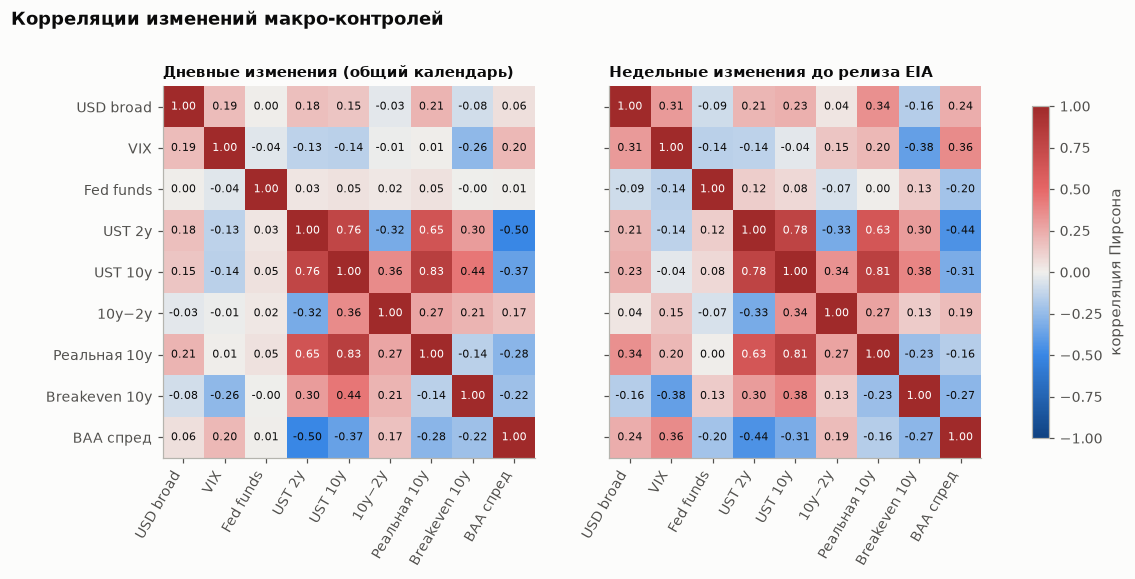

In [33]:
lvd = d.set_index("date")
print("Тождества FRED: max |T10Y2Y − (DGS10 − DGS2)| =",
      round((lvd["yield_curve_10y2y"] - (lvd["treasury_10y"] - lvd["treasury_2y"])).abs().max(), 4),
      "| max |T10YIE − (DGS10 − DFII10)| =",
      round((lvd["breakeven_10y"] - (lvd["treasury_10y"] - lvd["real_yield_10y"])).abs().max(), 4))
idn = (lvd["breakeven_10y"] - (lvd["treasury_10y"] - lvd["real_yield_10y"])).abs()
print("  доля дней, где breakeven-тождество выполняется точно (до 0.005):", f"{(idn.dropna() < 0.005).mean():.1%}")
# общий календарь: дни, где наблюдаются все ряды; изменения между соседними такими днями
common = lvd[LEVELS].dropna().reset_index()
cd = changes(common).set_index("date")[LEVELS].dropna()
cw = wkly[LEVELS].dropna()
print("дневных изменений на общем календаре:", len(cd), "| недельных (до релиза):", len(cw))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for ax, (frame, t) in zip(axes, ((cd, "Дневные изменения (общий календарь)"), (cw, "Недельные изменения до релиза EIA"))):
    cm = frame.corr()
    im = ax.imshow(cm.to_numpy(), cmap=u.DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(LEVELS)), [LABEL[c] for c in LEVELS], rotation=60, ha="right")
    ax.set_yticks(range(len(LEVELS)), [LABEL[c] for c in LEVELS] if ax is axes[0] else [])
    ax.grid(False)
    for i in range(len(LEVELS)):
        for j in range(len(LEVELS)):
            ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(cm.iloc[i, j]) > 0.6 else u.INK)
    ax.set_title(t, fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="корреляция Пирсона")
fig.suptitle("Корреляции изменений макро-контролей", x=0.01, ha="left", fontweight="bold")
plt.show()

In [34]:
def vif(frame: pd.DataFrame) -> pd.Series:
    X = sm.add_constant(frame.dropna()).to_numpy()
    with np.errstate(divide="ignore"):
        return pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=frame.columns)


SETS = {
    "все 9": LEVELS,
    "без тождеств (−10y−2y, −breakeven)": ["usd_broad", "vix", "fed_funds", "treasury_2y", "treasury_10y",
                                           "real_yield_10y", "baa_spread"],
    "компактный": ["usd_broad", "vix", "treasury_2y", "breakeven_10y", "baa_spread"],
    "компактный + реальная 10y": ["usd_broad", "vix", "treasury_2y", "breakeven_10y", "real_yield_10y", "baa_spread"],
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # в полном наборе матрица вырождена из-за тождеств — предупреждения ожидаемы
    vif_tab = pd.concat({(k, freq): vif(fr[v]) for k, v in SETS.items()
                         for freq, fr in (("день", cd), ("неделя", cw))}, axis=1)
# VIF > 1000 означает точную линейную зависимость (численно получаются 1e5…1e15) — показываем как inf
vif_tab = vif_tab.mask(vif_tab >= 1e3, np.inf).loc[LEVELS].T
vif_tab.round(2)

usd_broad   vix  fed_funds  treasury_2y  treasury_10y  yield_curve_10y2y  real_yield_10y  breakeven_10y  baa_spread
все 9                              день         1.12  1.13       1.01          inf           inf                inf             inf            inf        1.39
                                   неделя       1.34  1.39       1.06          inf           inf                inf             inf            inf        1.55
без тождеств (−10y−2y, −breakeven) день         1.12  1.13       1.01         2.83          4.55                NaN            3.39            NaN        1.39
                                   неделя       1.34  1.39       1.06         3.00          4.65                NaN            3.59            NaN        1.55
компактный                         день         1.11  1.13        NaN         1.50           NaN                NaN             NaN           1.17        1.39
                                   неделя       1.32  1.35        NaN         1.53           NaN                NaN             NaN           1.28        1.53
компактный + реальная 10y          день         1.12  1.13        NaN         2.83           NaN                NaN            2.27           1.47        1.39
                                   неделя       1.34  1.39        NaN         2.99           NaN                NaN            2.62           1.68        1.53

**Вывод.** Два ряда — точные линейные комбинации других: T10Y2Y = DGS10 − DGS2 и T10YIE = DGS10 − DFII10, расхождение 0.00 во всех днях. Поэтому в полном наборе VIF бесконечны. После удаления этих двух рядов остаётся сильная связь UST 10y с реальной доходностью (r = 0.83 по дням, 0.81 по неделям) и с 2y (0.76/0.78): VIF у 10y 4.6, у реальной 3.4–3.6, у 2y 2.8–3.0. Компактный набор **USD broad, VIX, UST 2y, breakeven 10y, BAA-спред** даёт VIF ≤ 1.50 по дням и ≤ 1.53 по неделям. С реальной доходностью 10y (вместе с breakeven она восстанавливает 10y) максимум VIF 2.8–3.0, это ещё приемлемо. Fed funds исключаем (на дневной и недельной частоте изменение почти всегда 0), 10y−2y и 10y — производные. Внутри компактного набора самые заметные связи — VIX × breakeven (−0.26 по дням, −0.38 по неделям) и VIX × BAA (0.20/0.36).

## Итоги

**Основные выводы**
- ~30% NA в дневном файле — это календарь: выходные плюс праздники, у каждого ряда свои. Изменения `1obs`/`5obs` считаются между соседними наблюдениями ряда (понедельник к пятнице), в выходные они NA. DFF публикуется 7 дней в неделю, поэтому пропусков у него нет.
- Для всех уровней, кроме VIX, ADF не отвергает единичный корень; все изменения стационарны.
- Дневная доходность WTI связана с макро: Δbreakeven ρ = 0.34, UST 10y 0.21, USD −0.16, VIX −0.14. Δ(F1−F2) связан слабо (|ρ| ≤ 0.12). Связи меняются по режимам: в 2026 году (F1 до $112.95, спред F1−F2 до $13.94) корреляции WTI с USD и VIX сменили знак на положительный (+0.30, +0.38).
- Изменения макро за неделю до релиза не предсказывают surprise (все |r| ≤ 0.06, p ≥ 0.16) и почти не связаны с Δ(F1−F2) в день релиза. Сам surprise с этим Δ тоже почти не связан (r = 0.01).
- Компактный набор контролей: **Δ USD broad (%), ΔVIX, ΔUST 2y, Δbreakeven 10y, ΔBAA-спред** (VIF ≤ 1.53); по желанию добавить Δреальной доходности 10y (VIF ≤ 3.0).

**Проблемы качества данных**
- `yield_curve_10y2y` ≡ `treasury_10y − treasury_2y` и `breakeven_10y` ≡ `treasury_10y − real_yield_10y` — точные тождества (расхождение 0.00), в одной регрессии их брать нельзя.
- `vix`: 32 значения в праздники при закрытой NYSE, 2022-05-30 … 2026-09-07; средний скачок +0.45 п., рост в 75% случаев. Эти дни лучше выбросить или привести VIX к календарю NYSE.
- `usd_broad`: 14 исторических будних NA вне праздников (2015-03-05, 2016-01-22/25/26, 2017-01-20, 2018-03-02, 2018-03-21, 2018-12-05, 2019-01-14, 2019-02-20, 2019-12-24, 2020-11-27, 2020-12-24, 2021-01-20). Ряд заканчивается 2026-10-30, публикуется раз в неделю.
- Все рыночные ряды пропущены 2018-12-05; строка 2026-11-03 неполная (есть только VIX, T10Y2Y и T10YIE).
- `fed_funds_change_5obs_bp` — изменение за 5 календарных дней, а не за неделю, как остальные `5obs`. У `fed_funds` 92% нулевых дневных изменений.
- Окна `1obs` разных рядов в один день не совпадают: VIX и UST — в 58 днях, USD и UST — в 23 днях из 2907.
- Месячный файл: за 2025-10 нет `cpi` и `unemployment` (шатдаун), отсюда NA в `cpi_yoy_pct` (2025-10, в будущем и 2026-10) и в `unemployment_change_1m_pp` (2025-10, 2025-11). Файл содержит текущую пересмотренную версию. Файла с первыми публикациями (`data/raw/fred/fred_monthly_controls_initial_2015_2026.parquet` из ноутбука 02) нет ни в `eda/data/processed`, ни на этой машине.
- Кривая WTI (Barchart nearby) не содержит идентификатора контракта, поэтому доходность F1 и `delta_spread_f1_f2` включают скачки роллов (вероятный пример — Δспреда +3.37 $ 2020-04-15). Доходность F1 доходит до 57% (2020-04-21). Здесь использованы Спирмен и винзоризация; роллы не удалялись.

**Следствия для моделирования**
- Брать изменения, а не уровни; уровень VIX — только как индикатор режима. Изменения пересчитывать на общем календаре или через as-of срезы, а не брать готовые `1obs` построчно.
- Срез контролей для релиза R: последнее наблюдение ≤ R−1. Это корректно, если считать ряды рыночными ценами, известными на закрытие. При строгой доступности именно FRED-рядов брать DGS2, DGS10, DFII10, BAA10Y и DFF на R−2, а DTWEXBGS на предыдущую пятницу: в среду в 10:30 ET значения за вторник ещё не опубликованы.
- Для прогноза surprise (M0–M5) макро-контроли практически бесполезны; их место — в части про цену и спред, как контроли общего рыночного фона. Δbreakeven сам отражает нефть, поэтому в регрессиях реакции брать его только до релиза.
- Связи нестабильны, а 2026 год — отдельный режим (вероятно, это тестовый период). Не стоит фиксировать коэффициенты, оценённые на 2015–2024; нужны скользящие или режимные оценки.
- Месячные ряды присоединять по `realtime_start ≤ R` из первых публикаций. Запасной вариант — сдвиг на 2 месяца: он покрывает обычные лаги (медиана 34–45 дней), но не шатдаун 2025 года (78–93 дня). Наивный join по месяцу релиза заглядывает вперёд на 1–2 месяца.
- Не сделано: ревизии INDPRO не оценены (нет первых публикаций); публикационные лаги дневных рядов выведены по одному снимку метаданных; роллы в кривой WTI не размечены.